# Détection de fraude bancaire — IEEE-CIS Fraud Detection

**Compétition :** [IEEE-CIS Fraud Detection (Kaggle)](https://www.kaggle.com/competitions/ieee-fraud-detection) — transactions e-commerce fournies par Vesta Corporation.

**Problème :** classification binaire — prédire si une transaction est frauduleuse (`isFraud = 1`).
**Métrique officielle :** ROC-AUC.

**Données :**

| Fichier | Contenu |
|---|---|
| `train_transaction.csv` | ~590 000 transactions, 394 colonnes (montant, carte, adresse, e-mails, C1–C14, D1–D15, M1–M9, V1–V339) + la cible |
| `train_identity.csv` | ~144 000 lignes, 41 colonnes (appareil, navigateur, réseau : id_01–id_38, DeviceType, DeviceInfo) |
| `test_transaction.csv` / `test_identity.csv` | jeu de test Kaggle sans la cible (pour la soumission) |

La plupart des colonnes sont **anonymisées** (V, C, D, id) : on ne connaît pas leur signification exacte.

**Chaîne de traitement :**

```
Data  →  EDA  →  Prétraitement  →  Transformation  →  ML  →  Évaluation  →  Déploiement
```

| Étape | Contenu |
|---|---|
| 1. Data | Chargement, fusion transaction + identité, réduction mémoire, structure |
| 2. EDA | Déséquilibre de la cible, montants, temps, variables catégorielles, valeurs manquantes, redondance |
| 3. Prétraitement | Doublons, tri temporel, suppression des colonnes vides / constantes / redondantes, harmonisation |
| 4. Transformation | Feature engineering (temps, montant, identifiant client, fréquences, agrégations), encodage, split **temporel** |
| 5. ML | Régression logistique, Random Forest, XGBoost, LightGBM + optimisation + validation croisée temporelle |
| 6. Évaluation | ROC-AUC, PR-AUC, seuil, matrice de confusion, vue métier (top-k %), stabilité, importance et explication |
| 7. Déploiement | Sauvegarde du pipeline, fonction de prédiction, application Streamlit, soumission Kaggle |

>  **Mémoire :** les données complètes occupent plusieurs Go. Le plus simple est d'exécuter ce notebook **sur Kaggle**. En local avec peu de RAM, mets `SAMPLE_ROWS = 200_000` dans la cellule de configuration.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os, gc, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
import lightgbm as lgb
from xgboost import XGBClassifier
import joblib

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4.5)

### Configuration

In [2]:
SAMPLE_ROWS = None      # None = toutes les données. Ex : 200_000 si ta machine a moins de 16 Go de RAM
RANDOM_STATE = 42
TUNING = True           # recherche d'hyperparamètres pour LightGBM (False = beaucoup plus rapide)
CV_TEMPORELLE = True    # validation croisée temporelle (plus long)

---
## 1. Data — Chargement et fusion

In [3]:
DOSSIERS = ["/kaggle/input/ieee-fraud-detection", "ieee-fraud-detection", "data", "."]
DATA_DIR = next((d for d in DOSSIERS if os.path.exists(os.path.join(d, "train_transaction.csv"))), None)
if DATA_DIR is None:
    raise FileNotFoundError(f"train_transaction.csv introuvable. Dossier actuel : {os.getcwd()} | contenu : {os.listdir()}")
print("Dossier des données :", DATA_DIR)

def reduire_memoire(df):
    """Convertit float64 -> float32 et réduit la taille des entiers."""
    avant = df.memory_usage(deep=True).sum() / 1024**2
    for c in df.columns:
        if df[c].dtype == "float64":
            df[c] = df[c].astype("float32")
        elif df[c].dtype == "int64":
            df[c] = pd.to_numeric(df[c], downcast="integer")
    apres = df.memory_usage(deep=True).sum() / 1024**2
    print(f"  mémoire : {avant:,.0f} Mo -> {apres:,.0f} Mo")
    return df

def charger(prefixe, nrows=None):
    tr = pd.read_csv(os.path.join(DATA_DIR, f"{prefixe}_transaction.csv"), nrows=nrows)
    idt = pd.read_csv(os.path.join(DATA_DIR, f"{prefixe}_identity.csv"))
    idt.columns = [c.replace("id-", "id_") for c in idt.columns]   # le test utilise 'id-01' au lieu de 'id_01'
    print(f"{prefixe}_transaction : {tr.shape} | {prefixe}_identity : {idt.shape}")
    df = tr.merge(idt, on="TransactionID", how="left")
    del tr, idt; gc.collect()
    return reduire_memoire(df)

t0 = time.time()
df_raw = charger("train", SAMPLE_ROWS)
print("Après fusion :", df_raw.shape, f"({time.time()-t0:.0f} s)")

Dossier des données : ieee-fraud-detection
train_transaction : (590540, 394) | train_identity : (144233, 41)
  mémoire : 1,984 Mo -> 1,073 Mo
Après fusion : (590540, 434) (6 s)


In [4]:
df_raw.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


In [5]:
# Les colonnes sont organisées en familles
def famille(c):
    for p in ["card", "addr", "dist", "C", "D", "M", "V", "id_"]:
        if c.startswith(p) and (p in ("card", "addr", "dist", "id_") or c[len(p):].isdigit()):
            return {"id_": "id (identité)"}.get(p, p)
    if c in ("P_emaildomain", "R_emaildomain"): return "email"
    if c in ("DeviceType", "DeviceInfo"): return "Device"
    return "transaction"

fam = pd.DataFrame({"famille": [famille(c) for c in df_raw.columns],
                    "manquants": df_raw.isna().mean().values,
                    "texte": [not pd.api.types.is_numeric_dtype(df_raw[c]) for c in df_raw.columns]})
resume = fam.groupby("famille").agg(nb_colonnes=("manquants", "size"),
                                    pct_manquants_moyen=("manquants", "mean"),
                                    nb_textuelles=("texte", "sum"))
resume["pct_manquants_moyen"] = (resume["pct_manquants_moyen"] * 100).round(1)
resume.sort_values("nb_colonnes", ascending=False)

,nb_colonnes,pct_manquants_moyen,nb_textuelles
famille,,,
V,339,43.0,0
id (identité),38,84.8,15
D,15,58.2,0
C,14,0.0,0
M,9,49.9,9
card,6,0.5,2
transaction,5,0.0,1
Device,2,78.0,2
addr,2,11.1,0


**Observations :**
- La table d'identité ne concerne qu'**environ un quart des transactions** : après la jointure, toutes ses colonnes sont vides pour les autres.
- Les **339 colonnes V** représentent l'essentiel du volume et contiennent beaucoup de valeurs manquantes.
- Les variables textuelles (`ProductCD`, `card4`, `card6`, e-mails, `M1–M9`, plusieurs `id_`, `DeviceType`, `DeviceInfo`) devront être encodées.

---
## 2. EDA — Analyse exploratoire
### 2.1 Variable cible

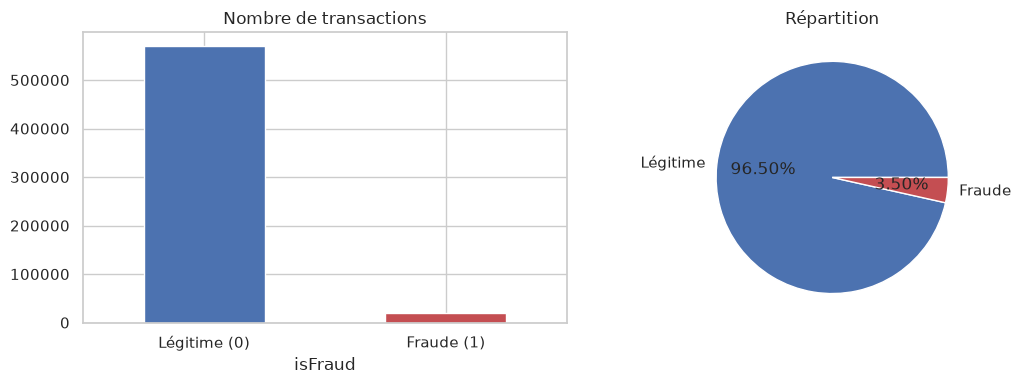

Taux de fraude : 3.50% | part du montant total : 3.87%


In [6]:
taux = df_raw["isFraud"].mean()
part_montant = df_raw.loc[df_raw.isFraud == 1, "TransactionAmt"].sum() / df_raw["TransactionAmt"].sum()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df_raw["isFraud"].value_counts().plot.bar(ax=ax[0], color=["#4C72B0", "#C44E52"])
ax[0].set_title("Nombre de transactions"); ax[0].set_xticklabels(["Légitime (0)", "Fraude (1)"], rotation=0)
ax[1].pie([1 - taux, taux], labels=["Légitime", "Fraude"], autopct="%.2f%%", colors=["#4C72B0", "#C44E52"])
ax[1].set_title("Répartition")
plt.tight_layout(); plt.show()
print(f"Taux de fraude : {taux:.2%} | part du montant total : {part_montant:.2%}")

Classe **très déséquilibrée** (environ 3,5 % de fraudes sur le jeu complet). Un modèle qui répond toujours « légitime » aurait ~96,5 % d'accuracy : **l'accuracy n'a aucun sens ici**. On utilisera le **ROC-AUC** (métrique officielle) et le **PR-AUC** (plus sensible à la classe rare).

### 2.2 Montant des transactions

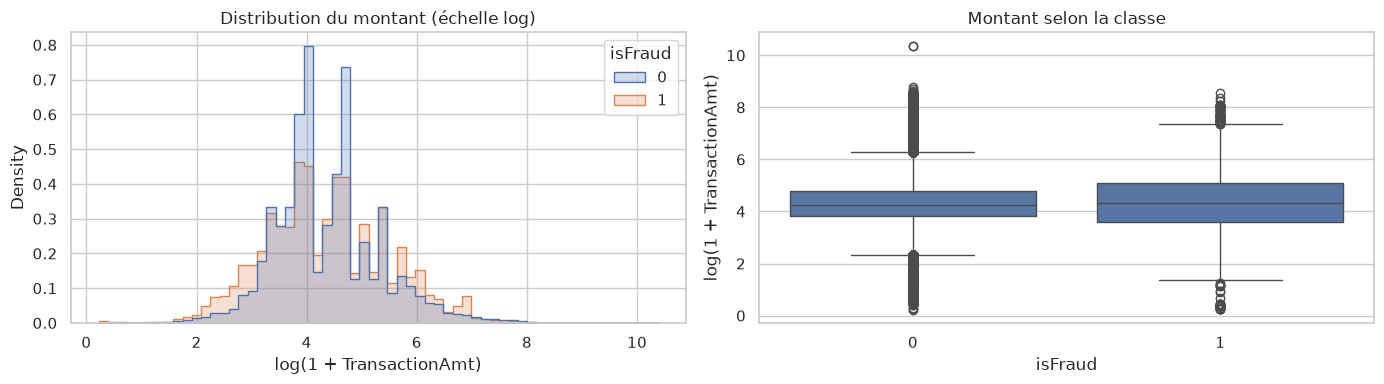

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,569877.0,134.51,239.40,0.25,43.97,68.5,120.0,31937.39
1,20663.0,149.24,232.21,0.29,35.04,75.0,161.0,5191.00


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=df_raw, x=np.log1p(df_raw["TransactionAmt"]), hue="isFraud", stat="density",
             common_norm=False, bins=60, element="step", ax=ax[0])
ax[0].set_xlabel("log(1 + TransactionAmt)"); ax[0].set_title("Distribution du montant (échelle log)")
sns.boxplot(data=df_raw, x="isFraud", y=np.log1p(df_raw["TransactionAmt"]), ax=ax[1])
ax[1].set_ylabel("log(1 + TransactionAmt)"); ax[1].set_title("Montant selon la classe")
plt.tight_layout(); plt.show()
df_raw.groupby("isFraud")["TransactionAmt"].describe().round(2)

Le montant est très asymétrique (quelques transactions énormes) : on travaillera aussi sur **log(montant)**.

### 2.3 Dimension temporelle

`TransactionDT` est un décalage **en secondes** depuis une date de référence inconnue. On en déduit le jour et l'heure.

Période couverte : 1 -> 182 jours (181 jours)


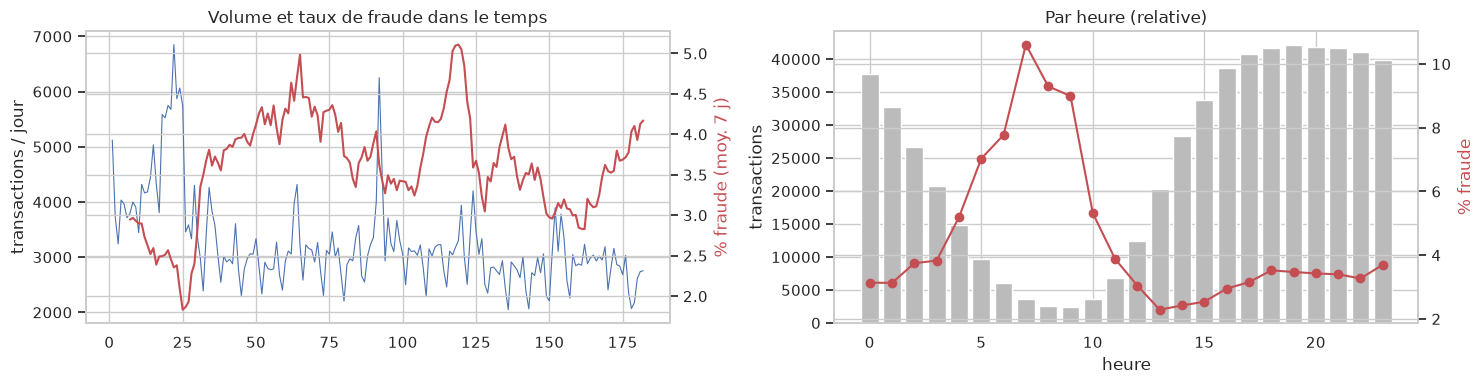

In [8]:
eda = df_raw[["TransactionDT", "isFraud", "TransactionAmt"]].copy()
eda["jour"] = eda["TransactionDT"] // 86400
eda["heure"] = (eda["TransactionDT"] // 3600) % 24
print(f"Période couverte : {eda.jour.min():.0f} -> {eda.jour.max():.0f} jours "
      f"({eda.jour.max() - eda.jour.min():.0f} jours)")

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
par_jour = eda.groupby("jour").agg(n=("isFraud", "size"), taux=("isFraud", "mean"))
ax[0].plot(par_jour.index, par_jour["n"], lw=.8); ax[0].set_ylabel("transactions / jour")
ax0b = ax[0].twinx(); ax0b.plot(par_jour.index, par_jour["taux"].rolling(7).mean() * 100, c="#C44E52")
ax0b.set_ylabel("% fraude (moy. 7 j)", color="#C44E52"); ax[0].set_title("Volume et taux de fraude dans le temps")
par_h = eda.groupby("heure")["isFraud"].agg(["size", "mean"])
ax[1].bar(par_h.index, par_h["size"], color="#BBBBBB"); ax[1].set_ylabel("transactions")
ax1b = ax[1].twinx(); ax1b.plot(par_h.index, par_h["mean"] * 100, c="#C44E52", marker="o")
ax1b.set_ylabel("% fraude", color="#C44E52"); ax[1].set_title("Par heure (relative)"); ax[1].set_xlabel("heure")
plt.tight_layout(); plt.show()

- Les données couvrent environ **6 mois** ; le jeu de test Kaggle se situe **après** dans le temps.
- ⇒ Le découpage train/test doit être **temporel** (passé → futur), pas aléatoire, sinon l'évaluation serait trop optimiste.
- Le taux de fraude varie selon l'heure : la fraude est relativement plus fréquente aux heures où il y a peu de transactions.

### 2.4 Variables catégorielles

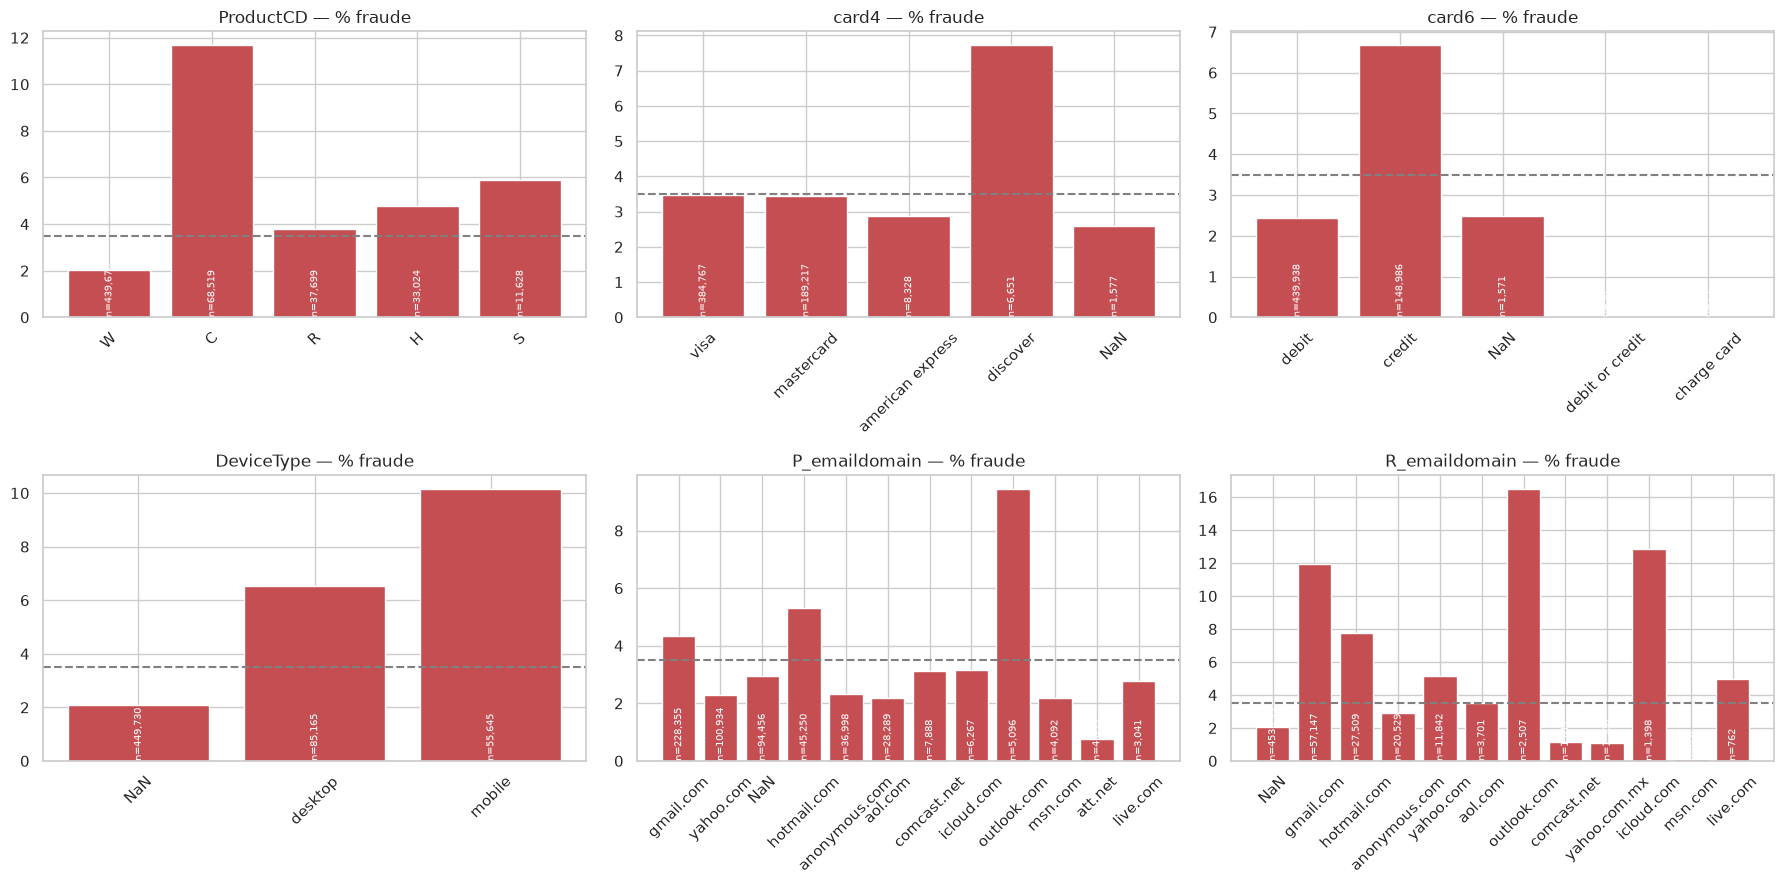

In [9]:
def taux_par(col, top=12, ax=None):
    g = df_raw.groupby(col, dropna=False)["isFraud"].agg(["size", "mean"]).sort_values("size", ascending=False).head(top)
    g.index = ["NaN" if pd.isna(v) else str(v) for v in g.index]
    ax.bar(g.index, g["mean"] * 100, color="#C44E52")
    ax.axhline(taux * 100, ls="--", c="grey")
    ax.set_title(f"{col} — % fraude"); ax.tick_params(axis="x", rotation=45)
    for i, n in enumerate(g["size"]):
        ax.text(i, 0, f"n={n:,}", ha="center", va="bottom", fontsize=7, rotation=90, color="white")

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flat, ["ProductCD", "card4", "card6", "DeviceType", "P_emaildomain", "R_emaildomain"]):
    taux_par(col, ax=ax)
plt.tight_layout(); plt.show()

**Observations (ligne grise = taux moyen) :**
- **`ProductCD`** : le produit **C** a un taux de fraude bien supérieur aux autres.
- **`card6`** : les cartes de **crédit** sont plus fraudées que les cartes de débit.
- **`DeviceType`** : les transactions **mobiles** sont plus risquées ; les transactions *sans* information d'identité (NaN) le sont moins.
- **E-mails** : certains domaines (ex. `protonmail.com`, messagerie anonyme) ont un taux de fraude très élevé.
- Le fait qu'une information soit **manquante** est lui-même informatif → on gardera les NaN pour les modèles à base d'arbres.

### 2.5 Valeurs manquantes

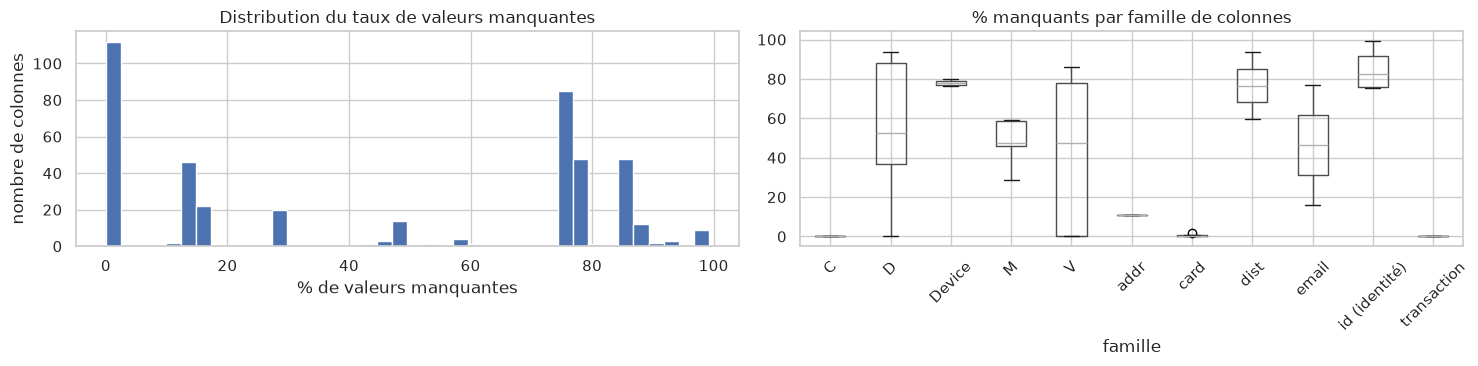

Colonnes > 90 % manquantes : 12 / 434
Colonnes sans valeur manquante : 20


In [10]:
manq = df_raw.isna().mean().sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].hist(manq * 100, bins=40, color="#4C72B0"); ax[0].set_xlabel("% de valeurs manquantes")
ax[0].set_ylabel("nombre de colonnes"); ax[0].set_title("Distribution du taux de valeurs manquantes")
fam.assign(manquants=fam.manquants * 100).boxplot(column="manquants", by="famille", ax=ax[1], rot=45)
ax[1].set_title("% manquants par famille de colonnes"); plt.suptitle("")
plt.tight_layout(); plt.show()
print("Colonnes > 90 % manquantes :", (manq > .9).sum(), "/", len(manq))
print("Colonnes sans valeur manquante :", (manq == 0).sum())

### 2.6 Redondance des colonnes V et corrélations

339 colonnes V, mais seulement 15 motifs distincts de valeurs manquantes
=> les colonnes V forment des blocs qui sont remplis (ou vides) en même temps.


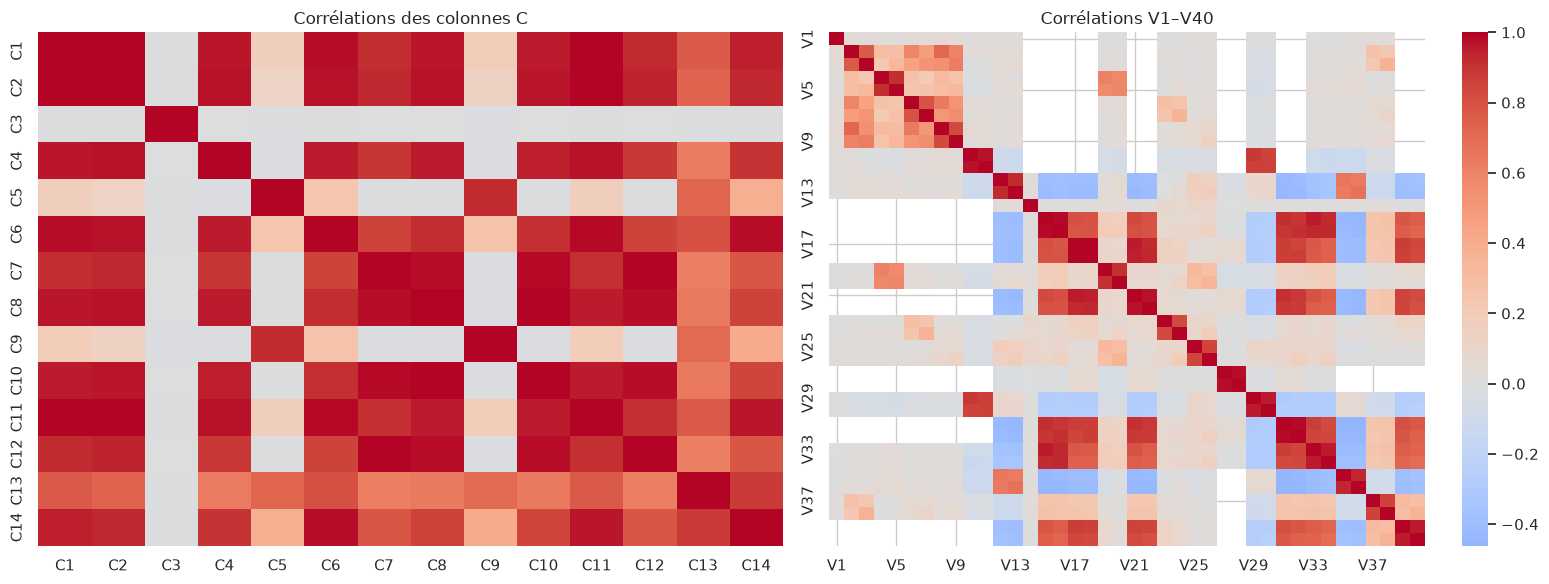

In [11]:
v_cols = [c for c in df_raw.columns if c.startswith("V") and c[1:].isdigit()]
motifs = df_raw[v_cols].isna().sum()
print(f"{len(v_cols)} colonnes V, mais seulement {motifs.nunique()} motifs distincts de valeurs manquantes")
print("=> les colonnes V forment des blocs qui sont remplis (ou vides) en même temps.")

ech = df_raw.sample(min(len(df_raw), 100_000), random_state=RANDOM_STATE)
c_cols = [f"C{i}" for i in range(1, 15) if f"C{i}" in df_raw]
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(ech[c_cols].corr(), cmap="coolwarm", center=0, ax=ax[0], cbar=False)
ax[0].set_title("Corrélations des colonnes C")
sns.heatmap(ech[v_cols[:40]].corr(), cmap="coolwarm", center=0, ax=ax[1], xticklabels=4, yticklabels=4)
ax[1].set_title("Corrélations V1–V40")
plt.tight_layout(); plt.show()

Beaucoup de colonnes C et V sont **presque identiques** (corrélation > 0.95). Les garder toutes alourdit le modèle sans apporter d'information : on les réduira au prétraitement.

### 2.7 Corrélation des variables numériques avec la cible

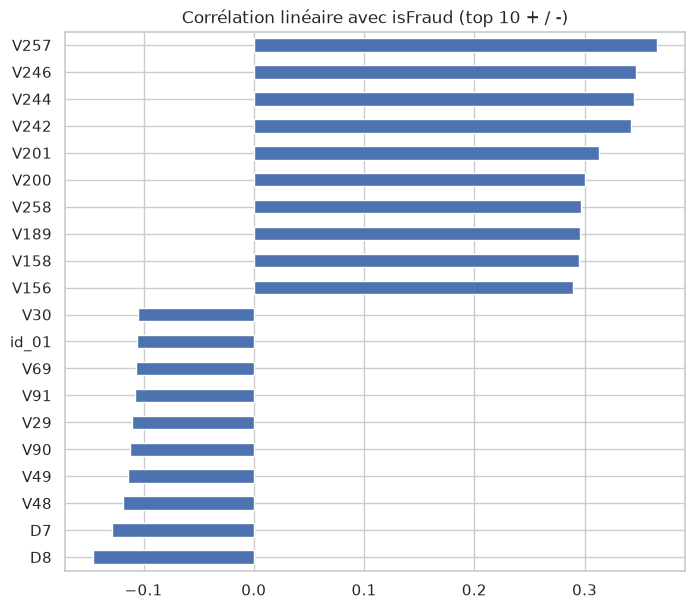

In [12]:
num = ech.select_dtypes("number").drop(columns=["isFraud", "TransactionID"])
corr_cible = num.corrwith(ech["isFraud"]).dropna().sort_values()
pd.concat([corr_cible.head(10), corr_cible.tail(10)]).plot.barh(figsize=(8, 7), color="#4C72B0")
plt.title("Corrélation linéaire avec isFraud (top 10 + / -)"); plt.show()
del eda, ech, num
_ = gc.collect()

---
## 3. Prétraitement — Nettoyage

Toutes les décisions de cette étape sont **non supervisées** (elles n'utilisent pas `isFraud`) : pas de risque de fuite de la cible.

### 3.1 Doublons et ordre temporel

In [13]:
df = df_raw.copy()
print("Doublons de TransactionID :", df["TransactionID"].duplicated().sum())
print("Lignes dupliquées :", df.drop(columns="TransactionID").duplicated().sum())
df = df.sort_values("TransactionDT").reset_index(drop=True)

Doublons de TransactionID : 0
Lignes dupliquées : 3


### 3.2 Colonnes presque vides ou presque constantes

In [14]:
PROTEGEES = ["isFraud", "TransactionID", "TransactionDT", "TransactionAmt", "card1", "addr1", "D1"]

trop_vides = [c for c in df.columns if c not in PROTEGEES and df[c].isna().mean() > 0.90]
quasi_constantes = [c for c in df.columns if c not in PROTEGEES + trop_vides
                    and df[c].value_counts(dropna=False, normalize=True).iloc[0] > 0.99]
print(f"{len(trop_vides)} colonnes > 90 % vides :", trop_vides)
print(f"{len(quasi_constantes)} colonnes avec une valeur > 99 % :", quasi_constantes)
df = df.drop(columns=trop_vides + quasi_constantes)
print("Dimensions :", df.shape)

12 colonnes > 90 % vides : ['dist2', 'D7', 'id_07', 'id_08', 'id_18', 'id_21', 'id_22', 'id_23', 'id_24', 'id_25', 'id_26', 'id_27']
15 colonnes avec une valeur > 99 % : ['C3', 'V107', 'V108', 'V110', 'V111', 'V112', 'V113', 'V114', 'V117', 'V118', 'V119', 'V120', 'V121', 'V122', 'V305']
Dimensions : (590540, 407)


### 3.3 Réduction des colonnes V redondantes

Pour chaque bloc de colonnes V ayant le même motif de valeurs manquantes, on garde une seule colonne parmi celles corrélées à plus de 0,95.

In [15]:
def reduire_V(data, seuil=0.95, n_ech=100_000):
    v = [c for c in data.columns if c.startswith("V") and c[1:].isdigit()]
    ech = data[v].sample(min(len(data), n_ech), random_state=RANDOM_STATE)
    a_garder = []
    nb_nan = ech.isna().sum()
    for _, cols in nb_nan.groupby(nb_nan).groups.items():   # blocs = même nombre de NaN
        cols = list(cols)
        corr = ech[cols].corr().abs()
        gardees = []
        for c in cols:
            if all(not (corr.loc[c, g] > seuil) for g in gardees):
                gardees.append(c)
        a_garder += gardees
    return v, a_garder

v_avant, v_gardees = reduire_V(df)
v_supprimees = [c for c in v_avant if c not in v_gardees]
df = df.drop(columns=v_supprimees)
print(f"Colonnes V : {len(v_avant)} -> {len(v_gardees)} ({len(v_supprimees)} supprimées)")
print("Dimensions :", df.shape)

Colonnes V : 325 -> 242 (83 supprimées)
Dimensions : (590540, 324)


### 3.4 Harmonisation des valeurs textuelles et valeurs manquantes

In [16]:
texte = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
for c in texte:
    df[c] = df[c].str.strip().str.lower()
print("Colonnes textuelles :", texte)

Colonnes textuelles : ['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'id_12', 'id_15', 'id_16', 'id_28', 'id_29', 'id_30', 'id_31', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType', 'DeviceInfo']


**Stratégie pour les valeurs manquantes :**
- **LightGBM / XGBoost** gèrent les NaN nativement et apprennent la meilleure direction pour eux. Comme l'absence d'information est elle-même un signal (vu en EDA), on **conserve les NaN**.
- Pour les modèles de référence (régression logistique, Random Forest), on imputera dans leur pipeline (médiane ou valeur sentinelle −999).

In [17]:
COLONNES_BRUTES = [c for c in df.columns if c != "isFraud"]
print(f"{len(COLONNES_BRUTES)} colonnes conservées après prétraitement")
del df_raw
_ = gc.collect()

323 colonnes conservées après prétraitement


---
## 4. Transformation — Feature engineering et encodage

On regroupe toutes les transformations dans une classe compatible scikit-learn (`fit` / `transform`), écrite dans un fichier `fraud_features.py`. Ainsi :
- tout ce qui est **appris** (fréquences, moyennes par client, encodages) l'est **uniquement sur le train** ;
- exactement le même objet est réutilisé pour le test, la soumission Kaggle et l'application de déploiement.

**Nouvelles variables :**

| Variable | Idée |
|---|---|
| `TransactionAmt_log`, `Amt_cents` | montant en log, partie décimale (les centimes varient selon le pays / la devise) |
| `hour`, `dow` | heure et jour de la semaine (relatifs) |
| `uid` (= `card1` + `addr1` + `D1n`) | **identifiant client approximatif** : `D1n = jour − D1` ≈ date d'ouverture du compte, constante pour un même client |
| `*_freq` | fréquence d'apparition (carte, adresse, e-mail, appareil, client…) |
| `*_mean_*`, `*_std_*`, `Amt_ratio_*` | statistiques du client / de la carte : un montant inhabituel pour ce client est suspect |
| `*_prov`, `Device_marque`, `OS`, `navigateur`, `email_match` | simplification des chaînes de caractères |
| catégorielles | encodage par entier (*label encoding*), adapté aux arbres ; modalité inconnue → −1 |

In [18]:
%%writefile fraud_features.py
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin


def _cle(s):
    """Convertit une colonne numérique en texte stable (315.0 -> '315', NaN -> 'nan')."""
    return pd.to_numeric(s, errors="coerce").round(0).astype("Int64").astype(str)


def _texte(s):
    return s.astype("object").where(s.notna(), np.nan)


class FraudFeatures(BaseEstimator, TransformerMixin):
    FREQ_COLS = ["card1", "card2", "card3", "card5", "addr1", "addr2", "P_emaildomain", "R_emaildomain",
                 "DeviceInfo", "id_30", "id_31", "id_33", "card1_addr1", "uid"]
    AGG_GROUPES = ["card1", "card1_addr1", "uid"]
    AGG_COLS = ["TransactionAmt", "D15", "C13", "dist1"]
    EXCLURE = ["TransactionID", "isFraud", "TransactionDT", "day", "D1n", "uid", "card1_addr1"]

    def __init__(self, colonnes=None):
        self.colonnes = colonnes

    # --- variables calculées ligne par ligne (rien n'est appris)
    def _base(self, X):
        X = X.copy()
        for c in X.columns:                       # même nettoyage du texte qu'au prétraitement
            if not pd.api.types.is_numeric_dtype(X[c]):
                X[c] = _texte(X[c]).str.strip().str.lower()
        X["TransactionAmt_log"] = np.log1p(X["TransactionAmt"])
        X["Amt_cents"] = (X["TransactionAmt"] - np.floor(X["TransactionAmt"])).round(3)
        X["day"] = X["TransactionDT"] // 86400
        X["hour"] = (X["TransactionDT"] // 3600) % 24
        X["dow"] = X["day"] % 7
        X["D1n"] = X["day"] - X["D1"]
        X["card1_addr1"] = _cle(X["card1"]) + "_" + _cle(X["addr1"])
        X["uid"] = X["card1_addr1"] + "_" + _cle(X["D1n"])
        for c in ["P_emaildomain", "R_emaildomain"]:
            if c in X:
                X[c + "_prov"] = _texte(X[c]).str.split(".").str[0]
        if "P_emaildomain" in X and "R_emaildomain" in X:
            X["email_match"] = np.where(X["R_emaildomain"].isna(), np.nan,
                                        (X["P_emaildomain"] == X["R_emaildomain"]).astype(float))
        if "DeviceInfo" in X:
            X["Device_marque"] = _texte(X["DeviceInfo"]).str.split(r"[ /_\-]").str[0]
        if "id_30" in X:
            X["OS"] = _texte(X["id_30"]).str.split(" ").str[0]
        if "id_31" in X:
            X["navigateur"] = _texte(X["id_31"]).str.split(" ").str[0]
        return X

    # --- application de ce qui a été appris au fit
    def _encoder(self, X):
        nouvelles = {}
        for c, vc in self.freq_maps_.items():
            nouvelles[c + "_freq"] = X[c].map(vc).astype("float32")
        for (g, c), agg in self.agg_maps_.items():
            m, s = X[g].map(agg["mean"]), X[g].map(agg["std"])
            nouvelles[f"{c}_mean_{g}"], nouvelles[f"{c}_std_{g}"] = m, s
            if c == "TransactionAmt":
                nouvelles[f"Amt_ratio_{g}"] = X[c] / m
        X = pd.concat([X, pd.DataFrame(nouvelles, index=X.index)], axis=1)
        for c, mp in self.cat_maps_.items():
            enc = X[c].map(mp).astype("float32")
            enc[X[c].notna() & enc.isna()] = -1          # modalité jamais vue au train
            X[c] = enc
        return X

    def fit(self, X, y=None):
        self.input_cols_ = list(self.colonnes) if self.colonnes is not None else list(X.columns)
        X = self._base(X.reindex(columns=self.input_cols_))
        self.freq_maps_ = {c: X[c].value_counts() for c in self.FREQ_COLS if c in X}
        self.agg_maps_ = {(g, c): X.groupby(g)[c].agg(["mean", "std"])
                          for g in self.AGG_GROUPES for c in self.AGG_COLS if c in X}
        self.cat_cols_ = [c for c in X.columns
                          if not pd.api.types.is_numeric_dtype(X[c]) and c not in self.EXCLURE]
        self.cat_maps_ = {c: {v: i for i, v in enumerate(X[c].dropna().unique())} for c in self.cat_cols_}
        Xt = self._encoder(X)
        self.features_ = [c for c in Xt.columns if c not in self.EXCLURE]
        return self

    def transform(self, X):
        X = self._base(X.reindex(columns=self.input_cols_))
        X = self._encoder(X)
        return X.reindex(columns=self.features_).astype("float32")

Writing fraud_features.py


In [19]:
from fraud_features import FraudFeatures

### 4.1 Découpage **temporel** train / test

Les 80 % de transactions les plus anciennes servent à l'entraînement, les 20 % les plus récentes au test : on simule la situation réelle où le modèle prédit des transactions **futures**.

In [20]:
coupe = int(len(df) * 0.8)
train_df, test_df = df.iloc[:coupe], df.iloc[coupe:]
y_train, y_test = train_df["isFraud"].values, test_df["isFraud"].values
jour = lambda d: d["TransactionDT"] // 86400
print(f"Train : {len(train_df):,} transactions (jours {jour(train_df).min():.0f}-{jour(train_df).max():.0f}) | fraude {y_train.mean():.2%}")
print(f"Test  : {len(test_df):,} transactions (jours {jour(test_df).min():.0f}-{jour(test_df).max():.0f}) | fraude {y_test.mean():.2%}")

Train : 472,432 transactions (jours 1-141) | fraude 3.51%
Test  : 118,108 transactions (jours 141-182) | fraude 3.44%


### 4.2 Apprentissage des transformations sur le train et application

In [21]:
t0 = time.time()
prep = FraudFeatures(colonnes=COLONNES_BRUTES).fit(train_df)
X_train = prep.transform(train_df)
X_test = prep.transform(test_df)
print(f"X_train {X_train.shape} | X_test {X_test.shape} ({time.time()-t0:.0f} s)")
print(f"{len(prep.cat_cols_)} colonnes catégorielles encodées, {len(prep.freq_maps_)} encodages de fréquence, "
      f"{len(prep.agg_maps_)} agrégations")
nouvelles = [c for c in prep.features_ if c not in COLONNES_BRUTES]
print("Nouvelles variables :", nouvelles)

X_train (472432, 372) | X_test (118108, 372) (56 s)
34 colonnes catégorielles encodées, 14 encodages de fréquence, 12 agrégations
Nouvelles variables : ['TransactionAmt_log', 'Amt_cents', 'hour', 'dow', 'P_emaildomain_prov', 'R_emaildomain_prov', 'email_match', 'Device_marque', 'OS', 'navigateur', 'card1_freq', 'card2_freq', 'card3_freq', 'card5_freq', 'addr1_freq', 'addr2_freq', 'P_emaildomain_freq', 'R_emaildomain_freq', 'DeviceInfo_freq', 'id_30_freq', 'id_31_freq', 'id_33_freq', 'card1_addr1_freq', 'uid_freq', 'TransactionAmt_mean_card1', 'TransactionAmt_std_card1', 'Amt_ratio_card1', 'D15_mean_card1', 'D15_std_card1', 'C13_mean_card1', 'C13_std_card1', 'dist1_mean_card1', 'dist1_std_card1', 'TransactionAmt_mean_card1_addr1', 'TransactionAmt_std_card1_addr1', 'Amt_ratio_card1_addr1', 'D15_mean_card1_addr1', 'D15_std_card1_addr1', 'C13_mean_card1_addr1', 'C13_std_card1_addr1', 'dist1_mean_card1_addr1', 'dist1_std_card1_addr1', 'TransactionAmt_mean_uid', 'TransactionAmt_std_uid', 'Am

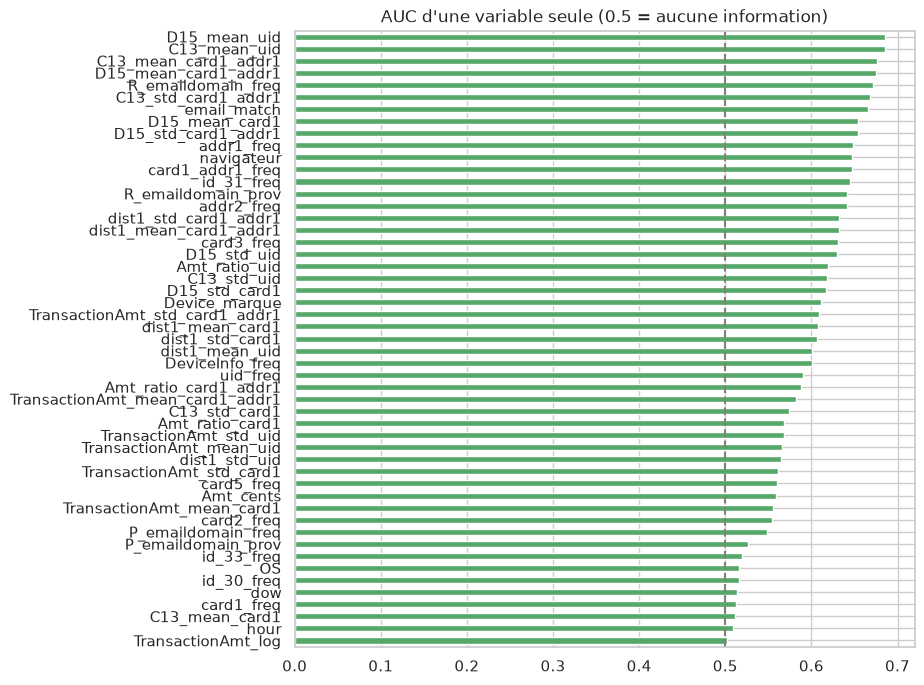

In [22]:
# Les nouvelles variables sont-elles utiles ? AUC de chaque variable seule sur le train
def auc_seule(col):
    x = X_train[col].fillna(-999)
    a = roc_auc_score(y_train, x)
    return max(a, 1 - a)

pd.Series({c: auc_seule(c) for c in nouvelles}).sort_values().plot.barh(figsize=(8, 8), color="#55A868")
plt.axvline(0.5, c="grey", ls="--"); plt.title("AUC d'une variable seule (0.5 = aucune information)"); plt.show()

---
## 5. ML — Entraînement et comparaison

On réserve les **15 % les plus récents du train** comme jeu de **validation** (arrêt anticipé, choix des hyperparamètres et du seuil). Le jeu de test n'est utilisé qu'à l'étape 6.

In [23]:
coupe_val = int(len(X_train) * 0.85)
X_fit, X_val = X_train.iloc[:coupe_val], X_train.iloc[coupe_val:]
y_fit, y_val = y_train[:coupe_val], y_train[coupe_val:]
print("fit :", X_fit.shape, "| validation :", X_val.shape)

resultats, modeles, temps = {}, {}, {}
def noter(nom, proba):
    resultats[nom] = {"ROC-AUC val": roc_auc_score(y_val, proba), "PR-AUC val": average_precision_score(y_val, proba)}

fit : (401567, 372) | validation : (70865, 372)


### 5.1 Modèles de référence (sur un échantillon)

La régression logistique et le Random Forest de scikit-learn sont lents sur 400 000 lignes × 300 colonnes : on les entraîne sur un échantillon de 150 000 transactions.

In [ ]:
idx = np.random.RandomState(RANDOM_STATE).choice(len(X_fit), min(len(X_fit), 150_000), replace=False)
X_ech, y_ech = X_fit.iloc[idx], y_fit[idx]

t0 = time.time()
modeles["Régression logistique"] = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("sc", StandardScaler()),
    ("lr", LogisticRegression(max_iter=1000, class_weight="balanced", C=0.1)),
]).fit(X_ech, y_ech)
temps["Régression logistique"] = time.time() - t0
noter("Régression logistique", modeles["Régression logistique"].predict_proba(X_val)[:, 1])

t0 = time.time()
modeles["Random Forest"] = Pipeline([
    ("imp", SimpleImputer(strategy="constant", fill_value=-999)),
    ("rf", RandomForestClassifier(n_estimators=200, max_depth=20, min_samples_leaf=10, max_features="sqrt",
                                  class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE)),
]).fit(X_ech, y_ech)
temps["Random Forest"] = time.time() - t0
noter("Random Forest", modeles["Random Forest"].predict_proba(X_val)[:, 1])
pd.DataFrame(resultats).T.round(4)

### 5.2 Gradient boosting : XGBoost et LightGBM (toutes les données, arrêt anticipé)

In [ ]:
t0 = time.time()
xgb = XGBClassifier(n_estimators=3000, learning_rate=0.05, max_depth=9, subsample=0.8, colsample_bytree=0.5,
                    min_child_weight=5, tree_method="hist", eval_metric="auc", early_stopping_rounds=100,
                    n_jobs=-1, random_state=RANDOM_STATE)
xgb.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=200)
modeles["XGBoost"], temps["XGBoost"] = xgb, time.time() - t0
noter("XGBoost", xgb.predict_proba(X_val)[:, 1])
print("meilleure itération :", xgb.best_iteration)

In [ ]:
PARAMS_LGB = dict(n_estimators=5000, learning_rate=0.03, num_leaves=256, max_depth=-1, min_child_samples=100,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.4, reg_alpha=0.1, reg_lambda=0.1,
                  n_jobs=-1, random_state=RANDOM_STATE, verbose=-1)

def entrainer_lgb(params, Xa=X_fit, ya=y_fit, log=200):
    m = lgb.LGBMClassifier(**params)
    m.fit(Xa, ya, eval_set=[(X_val, y_val)], eval_metric="auc",
          callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(log)])
    return m

t0 = time.time()
modeles["LightGBM"] = entrainer_lgb(PARAMS_LGB)
temps["LightGBM"] = time.time() - t0
noter("LightGBM", modeles["LightGBM"].predict_proba(X_val)[:, 1])
print("meilleure itération :", modeles["LightGBM"].best_iteration_)

In [ ]:
comparaison = pd.DataFrame(resultats).T.assign(**{"temps (s)": pd.Series(temps).round(0)})
comparaison.sort_values("ROC-AUC val", ascending=False).style.format("{:.4f}", subset=["ROC-AUC val", "PR-AUC val"]) \
    .highlight_max(subset=["ROC-AUC val", "PR-AUC val"], color="#c6efce")

Les modèles de **gradient boosting** sont nettement supérieurs : ils gèrent les NaN, les interactions entre variables et les colonnes très nombreuses. On continue avec **LightGBM** (en général le meilleur compromis précision / vitesse sur ce jeu).

### 5.3 Optimisation des hyperparamètres de LightGBM

In [ ]:
meilleurs = dict(PARAMS_LGB)
if TUNING:
    grille = [{"num_leaves": nl, "colsample_bytree": cs, "min_child_samples": 100}
              for nl in (128, 384) for cs in (0.3, 0.5)]
    essais = []
    for g in grille:
        p = {**PARAMS_LGB, **g, "learning_rate": 0.05}       # taux plus grand pour aller plus vite pendant la recherche
        m = entrainer_lgb(p, log=0)
        auc = roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])
        essais.append({**g, "AUC val": auc, "itérations": m.best_iteration_})
        print(g, f"-> AUC {auc:.4f}")
    essais = pd.DataFrame(essais).sort_values("AUC val", ascending=False)
    meilleurs.update(essais.iloc[0][["num_leaves", "colsample_bytree", "min_child_samples"]].to_dict())
    meilleurs["num_leaves"] = int(meilleurs["num_leaves"]); meilleurs["min_child_samples"] = int(meilleurs["min_child_samples"])
    display(essais.head())

t0 = time.time()
lgb_opt = entrainer_lgb(meilleurs)
temps["LightGBM optimisé"] = time.time() - t0
modeles["LightGBM optimisé"] = lgb_opt
noter("LightGBM optimisé", lgb_opt.predict_proba(X_val)[:, 1])
print("Paramètres retenus :", {k: meilleurs[k] for k in ("num_leaves", "colsample_bytree", "min_child_samples", "learning_rate")})
print(f"AUC validation : {resultats['LightGBM optimisé']['ROC-AUC val']:.4f} | itérations : {lgb_opt.best_iteration_}")

### 5.4 Validation croisée temporelle

Pour vérifier que la performance est **stable dans le temps**, on fait une validation croisée où chaque pli entraîne sur le passé et valide sur la période suivante (`TimeSeriesSplit`).

In [ ]:
N_ITER = max(lgb_opt.best_iteration_, 100)
if CV_TEMPORELLE:
    scores = []
    for k, (a, b) in enumerate(TimeSeriesSplit(n_splits=4).split(X_train)):
        m = lgb.LGBMClassifier(**{**meilleurs, "n_estimators": N_ITER}).fit(X_train.iloc[a], y_train[a])
        s = roc_auc_score(y_train[b], m.predict_proba(X_train.iloc[b])[:, 1])
        scores.append(s)
        print(f"pli {k+1} : entraînement {len(a):,} -> validation {len(b):,} | AUC = {s:.4f}")
    print(f"AUC moyenne = {np.mean(scores):.4f} ± {np.std(scores):.4f}")

### 5.5 Modèle final

On ré-entraîne LightGBM avec les meilleurs paramètres sur **tout le train** (fit + validation), avec un nombre d'arbres légèrement augmenté pour compenser les données en plus.

In [ ]:
t0 = time.time()
modele_final = lgb.LGBMClassifier(**{**meilleurs, "n_estimators": int(N_ITER * 1.1)}).fit(X_train, y_train)
print(f"Modèle final entraîné en {time.time()-t0:.0f} s sur {len(X_train):,} transactions")

---
## 6. Évaluation sur le jeu de test (période future)
### 6.1 Choix du seuil de décision (sur la validation)

Le modèle renvoie une probabilité. Le seuil 0.5 est inadapté avec 3,5 % de fraudes : on choisit le seuil qui **maximise le F1** sur la **validation** (jamais sur le test).

In [ ]:
p_val = lgb_opt.predict_proba(X_val)[:, 1]
prec, rec, seuils = precision_recall_curve(y_val, p_val)
f1s = 2 * prec * rec / (prec + rec + 1e-9)
SEUIL = float(seuils[np.argmax(f1s[:-1])])
print(f"Seuil retenu : {SEUIL:.3f} (F1 validation = {f1s[:-1].max():.3f})")

plt.plot(seuils, prec[:-1], label="Precision"); plt.plot(seuils, rec[:-1], label="Recall")
plt.plot(seuils, f1s[:-1], label="F1"); plt.axvline(SEUIL, c="grey", ls="--")
plt.xlabel("seuil"); plt.title("Precision / Recall / F1 selon le seuil (validation)"); plt.legend(); plt.show()

### 6.2 Métriques de tous les modèles sur le test

In [ ]:
modeles_test = {**{k: modeles[k] for k in ["Régression logistique", "Random Forest", "XGBoost", "LightGBM optimisé"]},
                "LightGBM final": modele_final}
probas_test = {nom: m.predict_proba(X_test)[:, 1] for nom, m in modeles_test.items()}

def metriques(y, p, seuil):
    pred = (p >= seuil).astype(int)
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
           ---------------------------------------------------------------------------
StopIteration                             Traceback (most recent call last)
Cell In[5], line 2
      1 DOSSIERS = ["/kaggle/input/ieee-fraud-detection", "ieee-fraud-detection", "data", "."]
----> 2 DATA_DIR = next(d for d in DOSSIERS if os.path.exists(os.path.join(d, "train_transaction.csv")))
      3 print("Dossier des données :", DATA_DIR)
      4 
      5 def reduire_memoire(df):

StopIteration:  "Precision": precision_score(y, pred, zero_division=0), "Recall": recall_score(y, pred),
            "F1": f1_score(y, pred)}

seuils_modeles = {}
for nom, m in modeles_test.items():
    if nom == "LightGBM final":
        seuils_modeles[nom] = SEUIL
    else:
        pv = m.predict_proba(X_val)[:, 1]
        pr, rc, th = precision_recall_curve(y_val, pv)
        seuils_modeles[nom] = th[np.argmax((2 * pr * rc / (pr + rc + 1e-9))[:-1])]

res_test = pd.DataFrame({n: metriques(y_test, p, seuils_modeles[n]) for n, p in probas_test.items()}).T
res_test.style.format("{:.4f}").highlight_max(axis=0, color="#c6efce")

> Remarque : les modèles autres que « LightGBM final » ont été entraînés sur la partie *fit* seulement (sans la validation), et la régression logistique / le Random Forest sur un échantillon.

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for nom, p in probas_test.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{nom} ({roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rc, pr, label=f"{nom} ({average_precision_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_title("Courbes ROC")
ax[0].set_xlabel("Taux de faux positifs"); ax[0].set_ylabel("Taux de vrais positifs (Recall)")
ax[1].axhline(y_test.mean(), c="k", ls="--", lw=1); ax[1].set_title("Courbes Precision-Recall")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 6.3 Matrice de confusion du modèle final

In [ ]:
p_final = probas_test["LightGBM final"]
pred_final = (p_final >= SEUIL).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_final), display_labels=["Légitime", "Fraude"]).plot(cmap="Blues", values_format=",")
plt.title(f"LightGBM final — seuil {SEUIL:.2f}"); plt.grid(False); plt.show()
print(classification_report(y_test, pred_final, target_names=["Légitime", "Fraude"], digits=3))

### 6.4 Vue métier : si l'équipe anti-fraude contrôle les k % de transactions les plus suspectes

En pratique, une banque ne peut vérifier manuellement qu'un petit pourcentage des transactions. La question utile est : *en contrôlant les k % les plus risquées, quelle part de la fraude bloque-t-on ?*

In [ ]:
montants = test_df["TransactionAmt"].values
ordre = np.argsort(-p_final)
lignes = []
for k in [0.5, 1, 2, 5, 10]:
    n = int(len(ordre) * k / 100)
    sel = ordre[:n]
    lignes.append({"% contrôlé": k, "transactions contrôlées": n,
                   "% des fraudes détectées": y_test[sel].sum() / y_test.sum() * 100,
                   "% du montant fraudé détecté": montants[sel][y_test[sel] == 1].sum() / montants[y_test == 1].sum() * 100,
                   "precision (%)": y_test[sel].mean() * 100})
pd.DataFrame(lignes).set_index("% contrôlé").round(1)

### 6.5 Stabilité dans le temps

In [ ]:
semaines = (test_df["TransactionDT"].values // (7 * 86400))
stab = pd.DataFrame({"semaine": semaines, "y": y_test, "p": p_final}).groupby("semaine").filter(lambda g: g.y.nunique() == 2)
auc_sem = stab.groupby("semaine").apply(lambda g: roc_auc_score(g.y, g.p))
auc_sem.plot(marker="o"); plt.axhline(roc_auc_score(y_test, p_final), ls="--", c="grey")
plt.ylabel("ROC-AUC"); plt.title("AUC par semaine sur la période de test"); plt.show()

Une légère baisse de l'AUC sur les semaines les plus éloignées du train est normale (**dérive temporelle** : les fraudeurs changent de méthode). En production, il faut **ré-entraîner le modèle régulièrement**.

### 6.6 Importance des variables

In [ ]:
imp = pd.Series(modele_final.booster_.feature_importance("gain"), index=prep.features_)
imp = (imp / imp.sum() * 100).sort_values(ascending=False)
imp.head(30)[::-1].plot.barh(figsize=(8, 10), color="#55A868")
plt.xlabel("% du gain total"); plt.title("LightGBM final — 30 variables les plus importantes"); plt.show()
print("Part des nouvelles variables dans le gain total :", round(imp[imp.index.isin(nouvelles)].sum(), 1), "%")

### 6.7 Explication d'une prédiction

LightGBM calcule directement les **valeurs SHAP** (`pred_contrib=True`) : la contribution de chaque variable à la prédiction d'une transaction précise.

In [ ]:
i = int(np.argmax(np.where(y_test == 1, p_final, -1)))       # fraude du test la mieux détectée
contrib = pd.Series(modele_final.predict(X_test.iloc[[i]], pred_contrib=True)[0][:-1], index=prep.features_)
top = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(12)[::-1]
top.plot.barh(color=np.where(top > 0, "#C44E52", "#4C72B0"))
plt.title(f"Transaction {int(test_df.iloc[i].TransactionID)} — probabilité de fraude {p_final[i]:.1%}\n(rouge = pousse vers la fraude)")
plt.xlabel("contribution (log-odds)"); plt.show()

---
## 7. Déploiement
### 7.1 Sauvegarde du pipeline

In [ ]:
os.makedirs("model", exist_ok=True)
joblib.dump({"prep": prep, "model": modele_final, "seuil": SEUIL,
             "auc_test": float(roc_auc_score(y_test, p_final))}, "model/fraud_model.joblib", compress=3)
print("Modèle sauvegardé :", round(os.path.getsize("model/fraud_model.joblib") / 1024**2, 1), "Mo")

### 7.2 Fonction de prédiction et test

In [ ]:
artefact = joblib.load("model/fraud_model.joblib")

def predire_fraude(transactions: pd.DataFrame) -> pd.DataFrame:
    """Prend des transactions brutes (colonnes transaction + identité) et renvoie un score de fraude."""
    X = artefact["prep"].transform(transactions)
    proba = artefact["model"].predict_proba(X)[:, 1]
    return pd.DataFrame({"TransactionID": transactions["TransactionID"].values,
                         "TransactionAmt": transactions["TransactionAmt"].values,
                         "proba_fraude": proba.round(4),
                         "alerte": np.where(proba >= artefact["seuil"], "FRAUDE", "ok")})

# Fichier d'exemple pour l'application : 300 transactions du test (dont des fraudes), sans la cible
exemple = pd.concat([test_df[test_df.isFraud == 1].head(30), test_df[test_df.isFraud == 0].head(270)])
exemple.drop(columns="isFraud").to_csv("exemple_transactions.csv", index=False)

res = predire_fraude(pd.read_csv("exemple_transactions.csv"))
res["vraie_classe"] = exemple["isFraud"].values
print(pd.crosstab(res["vraie_classe"], res["alerte"]))
res.sort_values("proba_fraude", ascending=False).head(10)

### 7.3 Application web Streamlit

On charge un fichier CSV de transactions, l'application renvoie le score de fraude de chacune, les alertes, et permet de télécharger le résultat.

```bash
pip install -r requirements.txt
streamlit run app.py
```

In [ ]:
%%writefile app.py
import joblib
import numpy as np
import pandas as pd
import streamlit as st
from fraud_features import FraudFeatures  # nécessaire pour recharger le pipeline

st.set_page_config(page_title="Détection de fraude", page_icon="💳", layout="wide")

@st.cache_resource
def charger():
    return joblib.load("model/fraud_model.joblib")

art = charger()
st.title(" Détection de fraude — IEEE-CIS")
st.caption(f"Modèle LightGBM — ROC-AUC sur le test : {art['auc_test']:.3f}")

fichier = st.file_uploader("Fichier CSV de transactions (colonnes transaction + identité)", type="csv")
if fichier is None and st.checkbox("Utiliser le fichier d'exemple", value=True):
    fichier = "exemple_transactions.csv"

seuil = st.slider("Seuil d'alerte", 0.01, 0.99, float(art["seuil"]), 0.01)

if fichier is not None:
    df = pd.read_csv(fichier)
    df.columns = [c.replace("id-", "id_") for c in df.columns]
    proba = art["model"].predict_proba(art["prep"].transform(df))[:, 1]
    res = pd.DataFrame({"TransactionID": df["TransactionID"], "Montant": df["TransactionAmt"],
                        "Produit": df.get("ProductCD"), "Probabilité de fraude": proba})
    res["Alerte"] = np.where(proba >= seuil, " FRAUDE", " ok")
    res = res.sort_values("Probabilité de fraude", ascending=False)

    c1, c2, c3 = st.columns(3)
    c1.metric("Transactions analysées", f"{len(res):,}")
    c2.metric("Alertes", f"{(proba >= seuil).sum():,}")
    c3.metric("Montant en alerte", f"{res.loc[proba[res.index] >= seuil, 'Montant'].sum():,.2f} $")

    st.dataframe(res.style.format({"Probabilité de fraude": "{:.1%}", "Montant": "{:,.2f}"})
                 .background_gradient(subset=["Probabilité de fraude"], cmap="Reds"),
                 height=450)
    st.bar_chart(np.histogram(proba, bins=20, range=(0, 1))[0])
    st.download_button("Télécharger les résultats (CSV)", res.to_csv(index=False).encode(), "predictions.csv")

In [ ]:
%%writefile requirements.txt
pandas
numpy
scikit-learn
lightgbm
joblib
matplotlib
streamlit

### 7.4 Validation sur Kaggle : fichier de soumission

Kaggle évalue la soumission sur son propre jeu de test (dont la cible est cachée). C'est la **validation officielle** du modèle.

Pour la soumission, on ré-entraîne le pipeline sur **toutes** les données d'entraînement (train + notre test interne), puisque plus de données récentes = meilleur modèle.

In [ ]:
if os.path.exists(os.path.join(DATA_DIR, "test_transaction.csv")) and SAMPLE_ROWS is None:
    prep_kaggle = FraudFeatures(colonnes=COLONNES_BRUTES).fit(df)
    X_all = prep_kaggle.transform(df)
    modele_kaggle = lgb.LGBMClassifier(**{**meilleurs, "n_estimators": int(N_ITER * 1.2)}).fit(X_all, df["isFraud"].values)
    del X_all; gc.collect()

    test_kaggle = charger("test")
    sub = pd.DataFrame({"TransactionID": test_kaggle["TransactionID"],
                        "isFraud": modele_kaggle.predict_proba(prep_kaggle.transform(test_kaggle))[:, 1]})
    sub.to_csv("submission.csv", index=False)
    print(sub.shape); display(sub.head())
else:
    print("Soumission ignorée (fichiers de test absents ou SAMPLE_ROWS activé).")

**Pour soumettre :** sur la page de la compétition → *Late Submission* → charger `submission.csv` (ou, depuis un notebook Kaggle : *Submit to competition*). Kaggle affiche alors le **score public** et le **score privé** (ROC-AUC).

### 7.5 Organisation du dépôt GitHub

```
fraud-detection/
├── README.md
├── ieee_fraud_pipeline.ipynb
├── fraud_features.py              ← transformations (fit / transform)
├── app.py                         ← application Streamlit
├── requirements.txt
├── exemple_transactions.csv
└── model/
    └── fraud_model.joblib
```

 Les fichiers CSV de la compétition (~1,3 Go) **ne doivent pas** aller sur GitHub (limite de 100 Mo par fichier, et les règles de la compétition interdisent leur diffusion) : il faut les mettre dans le `.gitignore`.

---
## Conclusion

In [ ]:
print(f"Transactions d'entraînement : {len(df):,} | taux de fraude : {df.isFraud.mean():.2%}")
print(f"Colonnes : 434 brutes -> {len(COLONNES_BRUTES)} après prétraitement -> {len(prep.features_)} variables finales")
print(f"Modèle final : LightGBM ({modele_final.n_estimators} arbres, {meilleurs['num_leaves']} feuilles)")
print(f"Seuil de décision : {SEUIL:.3f}")
res_test.loc[["LightGBM final"]].round(4)

| Étape | Ce qui a été fait |
|---|---|
| Data | Fusion transaction + identité, réduction mémoire (float32) |
| EDA | Cible très déséquilibrée, dimension temporelle, produits / cartes / e-mails / appareils à risque, colonnes V redondantes |
| Prétraitement | Tri temporel, suppression des colonnes vides, quasi constantes et redondantes, NaN conservés |
| Transformation | Identifiant client `uid`, fréquences, agrégations par client, variables temporelles, encodage ; split temporel |
| ML | 4 familles de modèles, LightGBM optimisé par grille, validation croisée temporelle |
| Évaluation | ROC-AUC, PR-AUC, seuil choisi sur la validation, vue « top k % », stabilité, importance, SHAP |
| Déploiement | Pipeline joblib, application Streamlit, soumission Kaggle |